## Project Scenario:

An international firm that is looking to expand its business in different countries across the world has recruited you. You have been hired as a junior Data Engineer and are tasked with creating a script that can extract the list of the top 10 largest economies of the world in descending order of their GDPs in Billion USD (rounded to 2 decimal places), as logged by the International Monetary Fund (IMF). 

The required data seems to be available on the URL mentioned below:


URL: https://web.archive.org/web/20230902185326/https://en.wikipedia.org/wiki/List_of_countries_by_GDP_%28nominal%29


## Objectives


 - Use Webscraping to extract required information from a website.
 - Use Pandas to load and process the tabular data as a dataframe.
 - Use Numpy to manipulate the information contatined in the dataframe.
 - Load the updated dataframe to CSV file.


---


# Setup


For this lab, we will be using the following libraries:

*   [`pandas`](https://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for managing the data.
*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for mathematical operations.


In [2]:
#Install required packages
!pip install pandas numpy 
!pip install lxml
!pip install matplotlib

### Importing Required Libraries




In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

# You can also use this section to suppress warnings generated by your code:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

---


# Exercises

### Exercise 1
Extract the required GDP data from the given URL using Web Scraping.


In [4]:
URL="https://web.archive.org/web/20230902185326/https://en.wikipedia.org/wiki/List_of_countries_by_GDP_%28nominal%29"




<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0101EN-SkillsNetwork/images/pandas_wbs_3.png">


In [5]:
tables = pd.read_html(URL)
df = tables[3]

# Replace the column headers with column numbers
df.columns = range(df.shape[1])

# Retain columns with index 0 and 2 (name of country and value of GDP quoted by IMF)
df = df[[0,2]]

# Retain the Rows with index 1 to 10, indicating the top 10 economies of the world.
df = df.iloc[1:11,:]

# Assign column names as "Country" and "GDP (Million USD)"
df.columns = ['Country','GDP (Million USD)']

### Exercise 2
Modify the GDP column of the DataFrame, converting the value available in Million USD to Billion USD. Use the `round()` method of Numpy library to round the value to 2 decimal places. Modify the header of the DataFrame to `GDP (Billion USD)`.


In [6]:
df['GDP (Million USD)'] = df['GDP (Million USD)'].astype(int)

# Convert the GDP value in Million USD to Billion USD


# Use numpy.round() method to round the value to 2 decimal places.
df[['GDP (Million USD)']] = np.round(df[['GDP (Million USD)']], 2)

# Rename the column header from 'GDP (Million USD)' to 'GDP (Billion USD)'
# Raw column ko float me divide karein taaki small values retain rahein
df['GDP (Billion USD)'] = df['GDP (Million USD)'] / 1000

# 2 decimal places tak round karein
df['GDP (Billion USD)'] = df['GDP (Billion USD)'].round(2)
df

,Country,GDP (Million USD),GDP (Billion USD)
1,United States,26854599,26854.60
2,China,19373586,19373.59
3,Japan,4409738,4409.74
4,Germany,4308854,4308.85
5,India,3736882,3736.88
6,United Kingdom,3158938,3158.94
7,France,2923489,2923.49
8,Italy,2169745,2169.74
9,Canada,2089672,2089.67
10,Brazil,2081235,2081.24


### Exercise 3


Load the DataFrame to the CSV file named "Largest_economies.csv"


In [7]:
# Load the DataFrame to the CSV file named "Largest_economies.csv"
df.to_csv("Largest_economies.csv")

<Axes: xlabel='Country'>

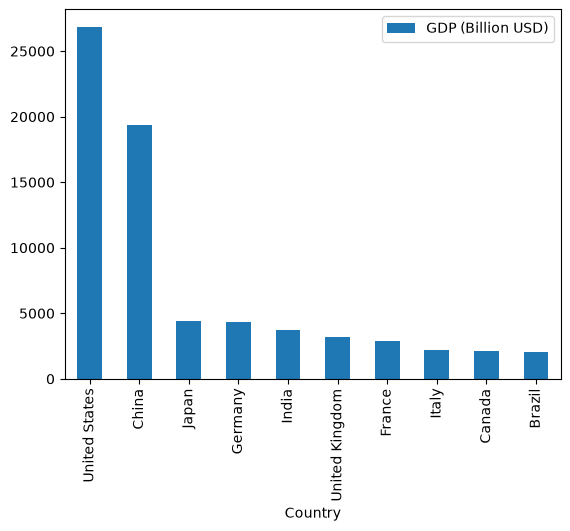

In [8]:
df.plot(x='Country', y='GDP (Billion USD)', kind='bar')  # Change 'bar' to 'line' or other types if needed